# TP3 · Big Data — Sentiment des avis Amazon avec Spark
**Question :** peut-on distinguer les avis positifs et négatifs à partir du titre et du texte, à l'échelle de quatre millions d'avis ?

**Parcours :** Spark (Data → EDA → Prétraitement) → Transformation → ML → Évaluation → Déploiement.

**Références :** [Sentiment Analysis with Amazon Reviews — MuonNeutrino](https://www.kaggle.com/code/muonneutrino/sentiment-analysis-with-amazon-reviews) est le point de départ Kaggle pour la classification de texte. Le [modèle de Yassir Acharki](https://huggingface.co/yassiracharki/Pre-trained_model_Binary_CNN_NLP_Amazon_Reviews) documente un CNN sur le jeu exact. Pour ce TP, on remplace l'approche neuronale par un modèle Spark ML sur CPU et on contrôle les doublons avant l'évaluation. Voir le README général pour les critères de choix.

## Configuration
Imports et fonctions réutilisées pour l'apprentissage et l'inférence.

In [1]:
import csv
import json
import os
import sys
from pathlib import Path
from time import perf_counter

import matplotlib.pyplot as plt
from pyspark import StorageLevel
from pyspark.ml import Pipeline, PipelineModel
from pyspark.ml.classification import LogisticRegression
from pyspark.ml.evaluation import BinaryClassificationEvaluator
from pyspark.ml.feature import HashingTF, IDF, RegexTokenizer, SQLTransformer
from pyspark.ml.functions import vector_to_array
from pyspark.sql import SparkSession, functions as F
from pyspark.sql.types import IntegerType, StringType, StructField, StructType


os.environ["PYSPARK_PYTHON"] = sys.executable

def create_spark(name):
    master = os.environ.get("TP3_SPARK_MASTER")
    builder = SparkSession.builder.appName(name)
    if master:
        builder = builder.master(master)
    elif "SPARK_MASTER" not in os.environ and "PYSPARK_SUBMIT_ARGS" not in os.environ:
        builder = builder.master("local[4]")
    spark = (builder
             .config("spark.ui.showConsoleProgress", "false")
             .config("spark.driver.host", "127.0.0.1")
             .config("spark.driver.bindAddress", "127.0.0.1")
             .config("spark.driver.memory", os.environ.get("TP3_SPARK_MEMORY", "6g"))
             .config("spark.sql.shuffle.partitions", os.environ.get("TP3_SPARK_SHUFFLE", "32"))
             .getOrCreate())
    spark.sparkContext.setLogLevel("ERROR")
    return spark


def score_reviews(model, rows):
    missing = sorted({"title", "body"} - set(rows.columns))
    if missing:
        raise ValueError(f"Colonnes d'entrée absentes : {', '.join(missing)}")
    return model.transform(rows.select("title", "body")).select(
        "title", "body",
        F.when(F.col("prediction") == 1.0, "positif").otherwise("négatif").alias("sentiment"),
        vector_to_array("probability")[1].alias("score_positif"),
    )

fraction = float(os.environ.get("TP3_BIG_FRACTION", "1"))
assert 0 < fraction <= 1

TP = next((p for p in (Path.cwd(), Path.cwd() / "big", Path.cwd() / "TP3" / "big") if (p / "amazon_reviews_dataset").is_dir()), None)
if TP is None:
    raise FileNotFoundError("Ouvrir ce notebook depuis bigData/, TP3/ ou TP3/big/.")
ARTIFACTS = TP / ("artefacts" if fraction == 1 else "artefacts/rapide")
MODEL_NAME = "modele_sentiment_spark"

## 1. Data — Ingestion Spark
[Amazon Reviews Polarity — Kaggle](https://www.kaggle.com/datasets/yacharki/amazon-reviews-for-sa-binary-negative-positive-csv/data) fournit **3,6 M** d'avis pour apprendre et **400 000** pour tester. La classe 1 correspond aux notes 1–2 (négatif), la classe 2 aux notes 4–5 (positif). Les notes de 3 sont exclues par les auteurs.

Les CSV sont lus avec un schéma explicite et l'échappement des guillemets du format source. En mode complet (par défaut), on utilise les deux ensembles entiers. Pour une répétition rapide, définir `TP3_BIG_FRACTION=0.02` avant le lancement : Spark lit les CSV, puis réduit les volumes transmis aux étapes suivantes.

Dans un clone GitHub, Spark lit directement les morceaux `train-*.csv.gz` et `test.csv.gz`. Si les CSV d’origine sont présents, ils sont utilisés en priorité.

In [2]:
data = TP / "amazon_reviews_dataset"
train_csv = data / "train.csv"
test_csv = data / "test.csv"
paths = {
    "train": [train_csv] if train_csv.is_file() else sorted(data.glob("train-*.csv.gz")),
    "test": [test_csv] if test_csv.is_file() else [data / "test.csv.gz"],
}
if not all(files and all(path.is_file() for path in files) for files in paths.values()):
    raise FileNotFoundError("Jeux train ou test manquants dans amazon_reviews_dataset/.")

spark = create_spark("TP3 Amazon Polarity")
schema = StructType([
    StructField("class_index", IntegerType()),
    StructField("review_title", StringType()),
    StructField("review_text", StringType()),
])

def read_reviews(files):
    rows = (spark.read.schema(schema)
            .options(header=True, enforceSchema=False, quote='"', escape='"', mode="FAILFAST")
            .csv([path.resolve().as_uri() for path in files])
            .selectExpr("class_index", "review_title as title", "review_text as body"))
    return rows if fraction == 1 else rows.sample(False, fraction, seed=42)

raw = {split: read_reviews(files) for split, files in paths.items()}
print(f"Spark {spark.version} | {spark.sparkContext.master} | fraction analysée : {fraction:.1%}")
for split, files in paths.items():
    size_mb = sum(path.stat().st_size for path in files) / 1e6
    print(f"{split} : {len(files)} fichier(s), {size_mb:.1f} Mo sur disque, "
          f"{raw[split].rdd.getNumPartitions()} partitions de lecture")
raw["train"].printSchema()

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
26/11/12 23:54:32 WARN Utils: Your hostname, LAPTOP-K2VAL7B9, resolves to a loopback address: 127.0.1.1; using 10.255.255.254 instead (on interface lo)
26/11/12 23:54:32 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address


Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


26/11/12 23:54:33 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Spark 4.0.1 | local[4] | fraction analysée : 100.0%


train : 11 fichier(s), 618.2 Mo sur disque, 6 partitions de lecture
test : 1 fichier(s), 70.7 Mo sur disque, 1 partitions de lecture
root
 |-- class_index: integer (nullable = true)
 |-- title: string (nullable = true)
 |-- body: string (nullable = true)



## 2. EDA — Analyse exploratoire distribuée
On explore uniquement le fichier d'apprentissage. Spark compte les classes, les champs vides et les avis par tranche de longueur. Le pilote ne reçoit que les agrégats nécessaires aux graphiques.

Agrégation Spark : 19.1 s
Titres vides : 77
Textes absents ou vides : 0
Classes invalides : 0


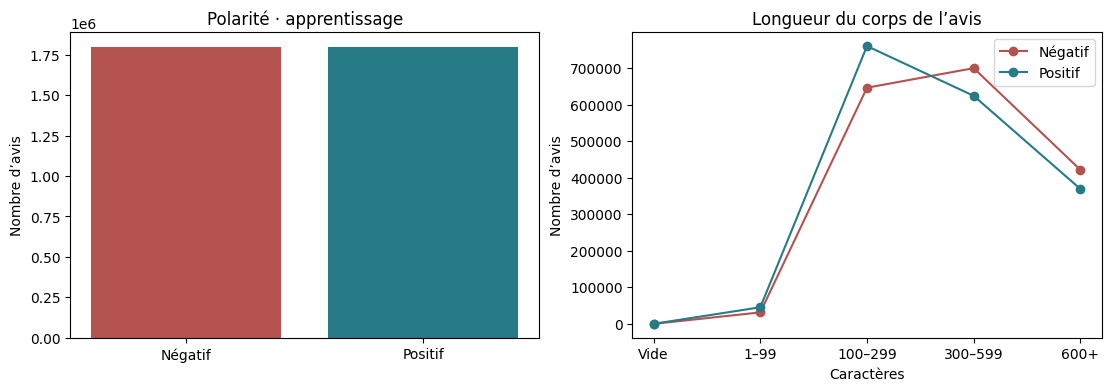

In [3]:
start = perf_counter()
profile = raw["train"].select(
    "class_index", F.length(F.coalesce("body", F.lit(""))).alias("length"),
    (F.length(F.trim(F.coalesce("title", F.lit("")))) == 0).cast("int").alias("title_vide"),
).withColumn("tranche",
    F.when(F.col("length") == 0, 0)
    .when(F.col("length") < 100, 1).when(F.col("length") < 300, 2)
    .when(F.col("length") < 600, 3).otherwise(4),
).groupBy("class_index", "tranche").agg(F.count("*").alias("n"), F.sum("title_vide").alias("titles")).collect()
print(f"Agrégation Spark : {perf_counter() - start:.1f} s")
class_names = ["Négatif", "Positif"]
counts = [sum(r.n for r in profile if r.class_index == i) for i in [1, 2]]
print("Titres vides :", sum(r.titles for r in profile))
print("Textes absents ou vides :", sum(r.n for r in profile if r.tranche == 0))
print("Classes invalides :", sum(r.n for r in profile if r.class_index not in [1, 2]))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), layout="constrained")
axes[0].bar(class_names, counts, color=["#B45250", "#267B87"])
axes[0].set(title="Polarité · apprentissage", ylabel="Nombre d’avis")
bins = ["Vide", "1–99", "100–299", "300–599", "600+"]
for label, color, name in zip([1, 2], ["#B45250", "#267B87"], class_names):
    bins_n = {r.tranche: r.n for r in profile if r.class_index == label}
    axes[1].plot(bins, [bins_n.get(i, 0) for i in range(5)], marker="o", color=color, label=name)
axes[1].set(title="Longueur du corps de l’avis", xlabel="Caractères", ylabel="Nombre d’avis")
axes[1].legend()
ARTIFACTS.mkdir(parents=True, exist_ok=True)
fig.savefig(ARTIFACTS / "eda.png", dpi=120)
plt.show()

## 3. Prétraitement — Nettoyage avec Spark SQL
On combine titre et texte, on passe en minuscules et on normalise les espaces. On conserve les avis ayant un texte exploitable et une étiquette valide. Les doublons sont repérés par l'empreinte SHA-256 du texte normalisé ; on retire les groupes aux labels contradictoires et on exclut du test les textes déjà vus dans le fichier d'apprentissage analysé. Les quasi-doublons peuvent subsister. Les résultats concernent ce test nettoyé et peuvent différer des scores sur le test officiel brut.

In [4]:
normalize = SQLTransformer(statement=r"""
    SELECT *, trim(regexp_replace(
        regexp_replace(lower(concat_ws(' ', title, body)), r'\\[nr]', ' '),
        r'\s+', ' '
    )) AS text FROM __THIS__
""")

def collapse(rows):
    valid = (normalize.transform(rows)
             .where(F.col("class_index").isin(1, 2) & F.col("text").rlike(r"[\p{L}\p{N}]"))
             .withColumn("key", F.sha2("text", 256)))
    grouped = valid.groupBy("key").agg(
        F.min("class_index").alias("low"),
        F.max("class_index").alias("high"),
        F.min(F.struct("title", "body")).alias("review"),
    )
    return grouped

group_train = collapse(raw["train"]).persist(StorageLevel.DISK_ONLY)
group_test = collapse(raw["test"])
def consistent(groups):
    return groups.where(F.col("low") == F.col("high")).select(
        "key", "review.*", (F.col("low") - 1).cast("double").alias("label"),
    )

train = consistent(group_train).persist(StorageLevel.DISK_ONLY)
test = (consistent(group_test)
        .join(group_train.select("key"), "key", "left_anti")
        .persist(StorageLevel.DISK_ONLY))
train_counts = {int(r.label): r["count"] for r in train.groupBy("label").count().collect()}
assert set(train_counts) == {0, 1}, "Deux classes sont nécessaires à l'entraînement."
print("Apprentissage brut :", sum(r.n for r in profile))
print("Apprentissage après nettoyage :", train_counts)
print("Test après nettoyage et exclusion des textes déjà vus :", test.count())
print("Partitions après nettoyage :", train.rdd.getNumPartitions(), test.rdd.getNumPartitions())
group_train.unpersist()

Apprentissage brut : 3600000
Apprentissage après nettoyage : {1: 1799938, 0: 1799721}


Test après nettoyage et exclusion des textes déjà vus : 399914
Partitions après nettoyage : 32 32


DataFrame[key: string, low: int, high: int, review: struct<title:string,body:string>]

## 4. Transformation — Du texte au vecteur TF-IDF
`RegexTokenizer` découpe le texte en mots et conserve les négations. `HashingTF` donne à chaque document un vecteur creux de dimension fixe. Deux termes peuvent partager un indice ; un espace de 65 536 dimensions limite ces collisions. `IDF` réduit le poids des termes fréquents dans le corpus. Ses poids sont calculés uniquement sur l'apprentissage.

In [5]:
stages = [
    normalize,
    RegexTokenizer(inputCol="text", outputCol="tokens", pattern=r"[^\p{L}\p{N}']+", minTokenLength=1),
    HashingTF(inputCol="tokens", outputCol="tf", numFeatures=2**16),
    IDF(inputCol="tf", outputCol="features", minDocFreq=2),
]
print(" → ".join(type(stage).__name__ for stage in stages))

SQLTransformer → RegexTokenizer → HashingTF → IDF


## 5. ML — Régression logistique avec Spark ML
Une régression logistique régularisée apprend des poids sur les vecteurs TF-IDF. C'est un premier modèle rapide et adapté aux vecteurs creux. Le pipeline assemble la transformation et le classifieur pour que les mêmes opérations soient appliquées à de nouveaux avis. Les hyperparamètres sont fixés avant le test. On retient comme référence la classe majoritaire observée à l'apprentissage.

In [6]:
majority = max(train_counts, key=train_counts.get)
classifier = LogisticRegression(
    featuresCol="features", labelCol="label", maxIter=35, regParam=0.01, elasticNetParam=0.0,
)
started = perf_counter()
model = Pipeline(stages=[*stages, classifier]).fit(train)
fit_seconds = perf_counter() - started
print(f"Entraînement : {fit_seconds:.1f} s | Classe de la référence naïve : {class_names[majority]}")

Entraînement : 313.9 s | Classe de la référence naïve : Positif


## 6. Évaluation — Test officiel nettoyé
Les comptages de la matrice de confusion et les AUC sont calculés dans Spark. Le **F1 macro** est la moyenne du F1 négatif et du F1 positif, ce qui donne la même importance aux deux classes. On compare les décisions à la référence naïve, puis on regarde la précision et le rappel pour chaque classe. L'AUC PR considère les avis positifs comme la classe d'intérêt.

{
  "majoritaire": {
    "accuracy": 0.5000625134403897,
    "precision": [
      0.0,
      0.5000625134403897
    ],
    "rappel": [
      0.0,
      1.0
    ],
    "f1_macro": 0.33336111592676065
  },
  "logistique": {
    "accuracy": 0.9049120560920598,
    "precision": [
      0.9077862349320209,
      0.9020789783363208
    ],
    "rappel": [
      0.9013614628973851,
      0.9084617615585403
    ],
    "f1_macro": 0.904910780025528,
    "auc_roc": 0.9625558254882518,
    "auc_pr": 0.9611302887148303
  }
}


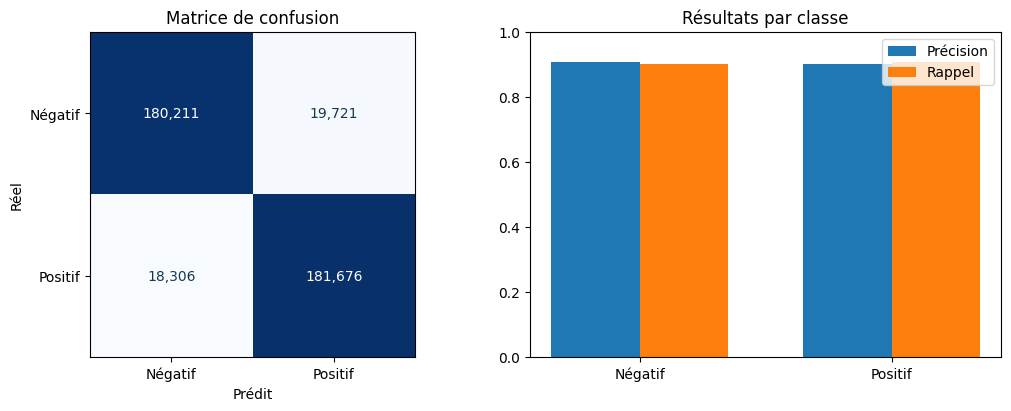

In [7]:
scored = model.transform(test).select("label", "prediction", "rawPrediction").persist(StorageLevel.DISK_ONLY)
matrix = [[0, 0], [0, 0]]
for row in scored.groupBy("label", "prediction").count().collect():
    matrix[int(row.label)][int(row.prediction)] = row["count"]
n_by_class = [sum(row) for row in matrix]
assert min(n_by_class) > 0, "Le test doit contenir les deux classes."
baseline = [[n if col == majority else 0 for col in range(2)] for n in n_by_class]

def divide(a, b):
    return a / b if b else 0.0

def summarize(cm):
    precision = [divide(cm[i][i], cm[0][i] + cm[1][i]) for i in range(2)]
    recall = [divide(cm[i][i], sum(cm[i])) for i in range(2)]
    f1 = [divide(2 * p * r, p + r) for p, r in zip(precision, recall)]
    return {
        "accuracy": divide(cm[0][0] + cm[1][1], sum(map(sum, cm))),
        "precision": precision, "rappel": recall, "f1_macro": sum(f1) / 2,
    }

results = {"majoritaire": summarize(baseline), "logistique": summarize(matrix)}
results["logistique"].update({
    key: BinaryClassificationEvaluator(metricName=metric).evaluate(scored)
    for key, metric in [("auc_roc", "areaUnderROC"), ("auc_pr", "areaUnderPR")]
})
print(json.dumps(results, indent=2))
fig, axes = plt.subplots(1, 2, figsize=(10, 4), layout="constrained")
axes[0].imshow(matrix, cmap="Blues")
for i in range(2):
    for j in range(2):
        axes[0].text(j, i, f"{matrix[i][j]:,}", ha="center", va="center",
                     color="white" if matrix[i][j] > max(map(max, matrix)) / 2 else "#15384b")
axes[0].set(xticks=[0, 1], yticks=[0, 1], xticklabels=class_names, yticklabels=class_names,
            xlabel="Prédit", ylabel="Réel", title="Matrice de confusion")
width = 0.35
for j, (key, title) in enumerate([("precision", "Précision"), ("rappel", "Rappel")]):
    axes[1].bar([i + (j - 0.5) * width for i in range(2)], results["logistique"][key], width, label=title)
axes[1].set(xticks=[0, 1], xticklabels=class_names, ylim=(0, 1), title="Résultats par classe")
axes[1].legend()
ARTIFACTS.mkdir(parents=True, exist_ok=True)
fig.savefig(ARTIFACTS / "evaluation.png", dpi=120)
plt.show()

## 7. Déploiement — Modèle Spark et prédiction par lot
On sauvegarde puis recharge le `PipelineModel` complet. On vérifie que les prédictions sur trois avis réels tirés du jeu de test, sans fournir leur étiquette au modèle sont identiques avant et après la sauvegarde. Le modèle et les métriques du mode rapide sont conservés à part.

In [8]:
out = ARTIFACTS
out.mkdir(parents=True, exist_ok=True)
model_uri = (out / MODEL_NAME).resolve().as_uri()
model.write().overwrite().save(model_uri)
reloaded = PipelineModel.load(model_uri)

example = [(row.title, row.body) for row in test.where(
    F.col("title").isNotNull() & F.col("body").isNotNull()
).orderBy("key").select("title", "body").take(3)]
assert len(example) == 3
with (out / "exemple_entree.csv").open("w", encoding="utf-8", newline="") as handle:
    writer = csv.writer(handle)
    writer.writerow(["title", "body"])
    writer.writerows(example)
example_df = spark.read.options(header=True, multiLine=True, quote='"', escape='"').csv((out / "exemple_entree.csv").resolve().as_uri())
before = score_reviews(model, example_df).orderBy("title").collect()
after = score_reviews(reloaded, example_df).orderBy("title").collect()
assert before == after and len(after) == len(example)
for row in after:
    print(f"{row.title} → {row.sentiment} (score positif = {row.score_positif:.3f})")

report = {"fraction": fraction, "n_train": sum(train_counts.values()), "n_test": sum(n_by_class),
          "secondes_fit": fit_seconds, "matrice": matrix, "modeles": results}
(out / "metriques_test.json").write_text(json.dumps(report, indent=2), encoding="utf-8")
config = {
    "modele": "Régression logistique",
    "dossier_modele": MODEL_NAME,
    "colonnes_entree": ["title", "body"],
    "classe_positive": 1,
    "fraction_donnees": fraction,
    "fichier_metriques": "metriques_test.json",
}
(out / "config.json").write_text(json.dumps(config, indent=2, ensure_ascii=False) + "\n", encoding="utf-8")

for frame in [train, test, scored]:
    frame.unpersist()

Bandido? → négatif (score positif = 0.460)
Purchased before. → négatif (score positif = 0.431)
worst vacuum ever → négatif (score positif = 0.049)


### Prédire avec le modèle sauvegardé
Pour prédire avec le modèle déjà exporté, exécuter **Configuration**, puis la cellule ci-dessous. Modifier `input_csv` pour lire un autre CSV avec les colonnes `title,body`. La cellule remplace le dossier de résultats `predictions/` de l'exécution choisie (complète ou rapide).

In [9]:
model_dir = ARTIFACTS
input_csv = model_dir / "exemple_entree.csv"
output_dir = model_dir / "predictions"

if input_csv.resolve().is_relative_to(output_dir.resolve()):
    raise ValueError("Le CSV d'entree ne doit pas se trouver dans le dossier de sortie.")

spark = create_spark("TP3 Prédiction Amazon")
try:
    model_lot = PipelineModel.load((model_dir / MODEL_NAME).resolve().as_uri())
    avis = (spark.read.options(header=True, mode="FAILFAST", multiLine=True, quote='"', escape='"')
           .csv(input_csv.resolve().as_uri()))
    predictions = score_reviews(model_lot, avis)
    predictions.write.mode("overwrite").option("header", True).csv(output_dir.resolve().as_uri())
    predictions.select("title", "sentiment", "score_positif").show(5, truncate=False)
finally:
    spark.stop()

+-----------------+---------+--------------------+
|title            |sentiment|score_positif       |
+-----------------+---------+--------------------+
|Purchased before.|négatif  |0.43061805526654484 |
|worst vacuum ever|négatif  |0.049458991651422424|
|Bandido?         |négatif  |0.459584909722242   |
+-----------------+---------+--------------------+



## Bilan
Spark effectue le traitement des textes, les agrégations et l'apprentissage par partitions. Le mode `local` montre cette organisation sur une seule machine ; il ne mesure pas la vitesse d'un cluster. Le corpus est en anglais et ne contient pas d'avis neutres : un avis mitigé ou ironique peut recevoir un score élevé pour l'une des deux classes sans que cette décision soit fiable.

Dans l'exécution complète fournie, la régression logistique classe correctement 90,49 % des 399 914 avis de test conservés. Les rappels sont proches pour les avis négatifs (90,14 %) et positifs (90,85 %). La référence majoritaire n'atteint que 50,01 % d'accuracy.